In [1]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import GeneralizedLinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline
import mlflow
import mlflow.spark

# Spark Oturumunu Baslat (Delta destegi ile)
spark = SparkSession.builder \
    .appName("NYC-Taxi-ModelTraining-GLR") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

# MLflow Ayarlari
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment("Taxi_Fare_Prediction")

print("Spark ve MLflow Hazir.")

Spark ve MLflow Hazir.


In [2]:
# Adim 5'te kaydettigimiz Gold tablosunu yukluyoruz.
gold_path = "/home/jovyan/work/data/delta/features"
df = spark.read.format("delta").load(gold_path)

print(f"Egitim icin yuklenen toplam kayit sayisi: {df.count()}")
df.printSchema()

Egitim icin yuklenen toplam kayit sayisi: 1798960
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- average_speed: double 

In [3]:
# Modelde kullanilacak ozellikler
feature_cols = [
    "trip_distance", 
    "trip_duration_min", 
    "average_speed", 
    "pickup_hour", 
    "day_of_week", 
    "is_airport_trip", 
    "is_rush_hour"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
final_df = assembler.transform(df).select("features", "total_amount")

# Veriyi %80 Egitim, %20 Dogrulama olarak ayiriyoruz
train_df, validation_df = final_df.randomSplit([0.8, 0.2], seed=42)

print(f"Egitim seti: {train_df.count()} kayit")
print(f"Dogrulama seti: {validation_df.count()} kayit")

Egitim seti: 1439385 kayit
Dogrulama seti: 359575 kayit


In [4]:
# Feature normalizasyonu (GLR icin onemli)
scaler = StandardScaler(inputCol="features", outputCol="features_scaled", withStd=True, withMean=False)
scaler_model = scaler.fit(train_df)

train_scaled = scaler_model.transform(train_df)
validation_scaled = scaler_model.transform(validation_df)

print("Feature'lar normalize edildi.")

Feature'lar normalize edildi.


In [5]:
with mlflow.start_run(run_name="GLR_Final"):
    # 1. Model Parametreleri
    family = "gaussian"
    link = "identity"
    max_iter = 50
    reg_param = 0.01
    
    glr = GeneralizedLinearRegression(
        featuresCol="features_scaled",
        labelCol="total_amount",
        family=family,
        link=link,
        maxIter=max_iter,
        regParam=reg_param
    )
    
    # 2. Modeli Egit
    print("GLR Modeli egitiliyor, lutfen bekleyin...")
    glr_model = glr.fit(train_scaled)
    
    # 3. Tahmin Yap
    predictions = glr_model.transform(validation_scaled)
    
    # 4. Metrikleri Hesapla
    evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
    evaluator_mae = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
    evaluator_r2 = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae = evaluator_mae.evaluate(predictions)
    r2 = evaluator_r2.evaluate(predictions)
    
    # 5. MLflow'a Logla
    mlflow.log_param("model_type", "GeneralizedLinearRegression")
    mlflow.log_param("family", family)
    mlflow.log_param("link", link)
    mlflow.log_param("maxIter", max_iter)
    mlflow.log_param("regParam", reg_param)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)
    
    mlflow.spark.log_model(glr_model, "glr_model")
    
    print(f"Model Basariyla Egitildi.")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R2 Score: {r2:.2f}")

GLR Modeli egitiliyor, lutfen bekleyin...
Model Basariyla Egitildi.
RMSE: 7.26
MAE: 3.39
R2 Score: 0.89
🏃 View run GLR_Final at: http://mlflow-server:5001/#/experiments/1/runs/9c4f7a37d2f74b729a1422caa70d6209
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


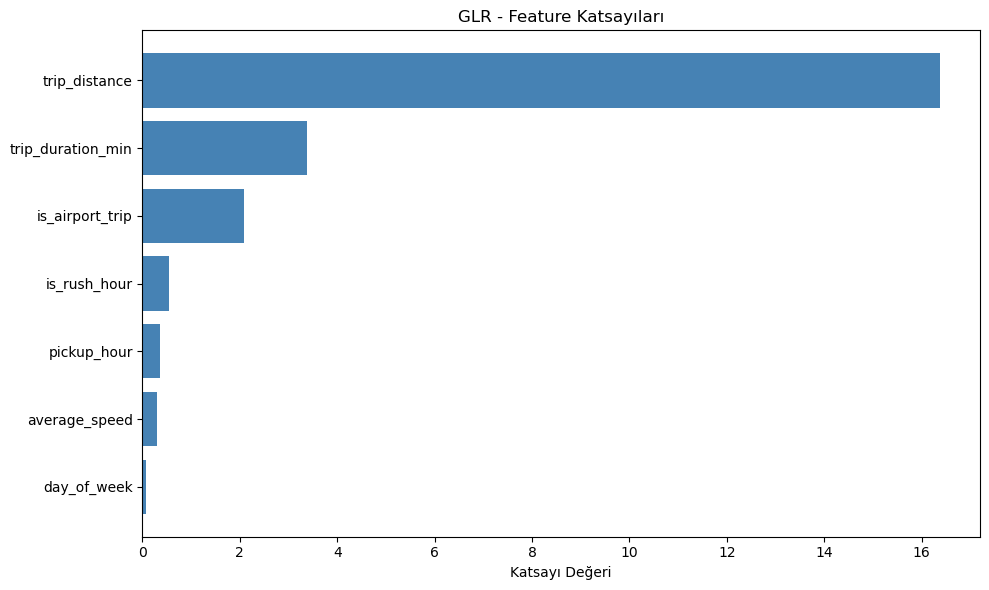

✅ Katsayı grafiği kaydedildi.


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# GLR Katsayıları (Feature Importance yerine)
coefficients = glr_model.coefficients.toArray()
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coefficients
})
importance_df = importance_df.reindex(importance_df["Coefficient"].abs().sort_values().index)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Coefficient"], color="steelblue")
plt.title("GLR - Feature Katsayıları")
plt.xlabel("Katsayı Değeri")
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/glr_coefficients.png")
plt.show()
print("✅ Katsayı grafiği kaydedildi.")

<module 'matplotlib.pyplot' from '/opt/conda/lib/python3.11/site-packages/matplotlib/pyplot.py'>

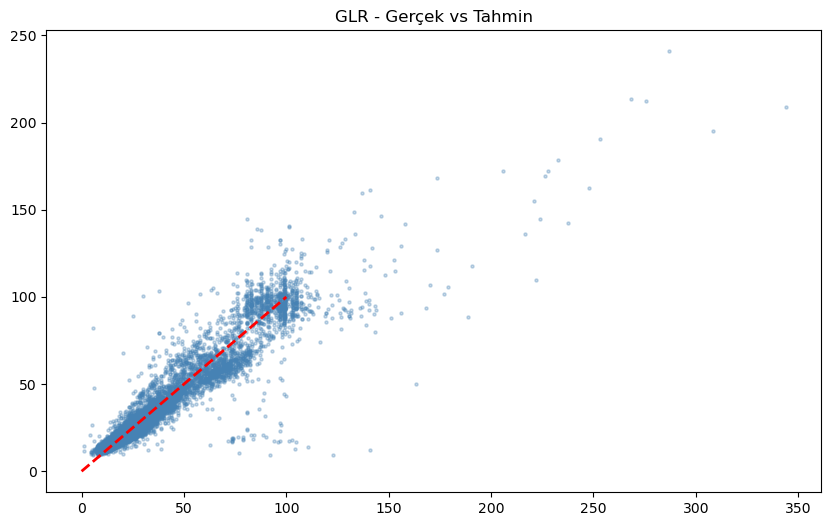

In [7]:
# Gerçek vs Tahmin scatter plot
sample = predictions.select("total_amount", "prediction") \
    .sample(fraction=0.05) \
    .toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(sample["total_amount"], sample["prediction"], alpha=0.3, s=5, color="steelblue")
plt.plot([0, 100], [0, 100], color="red", linewidth=2, linestyle="--", label="Mükemmel Tahmin")
plt.title("GLR - Gerçek vs Tahmin")
plt